# Remaining 37 ligands docked onto their holo ensembles of a-syn-C-term with AutoDock Vina-GPU

Populations of intermolecular interactions and dual residue contact probability for the 37 ligands outside the pilot, each docked onto 5,000 bound frames of its own MD simulation with a-syn-C-term (minimum protein-ligand heavy-atom distance < 6 A) -- holo docking. Box geometry as in the apo jobs: 20 boxes per frame, one per residue centroid, uniform 18.75 A edge, num_modes = 20.

Receptors are the all-atom PDB frames. The PDBQT receptors used for docking have all but ~29 polar hydrogens stripped, which under-counts H-bonds about threefold, so they are not used here.

Each frame is the receptor conformation that was docked against, plus the best-of-20
pose (the lowest-scoring of the 20 per-residue boxes). The example notebook reweights
t-SNE clusters by their MD populations; these ensembles are instead stride-sampled from
equilibrium trajectories, so every frame carries equal weight and the ensemble is treated
as a single cluster with weight 1.

Build the input once with
`python build_docked_trajectories.py --job holo_remaining37`.

In [1]:
import os, sys, json
import numpy as np
import mdtraj as md

for p in ("~/data/scripts", "~/data/scripts/docking_analysis"):
    p = os.path.expanduser(p)
    if os.path.isdir(os.path.join(p, "docking_tools")) and p not in sys.path:
        sys.path.insert(0, p)
from docking_tools import trajectory_analysis
from docking_tools import plotting

In [2]:
JOB = "holo_remaining37"
DATA = os.path.expanduser(f"~/data/docked_trajectories/{JOB}")
LIGANDS = [1, 2, 4, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 25, 26, 27, 29, 30, 33, 35, 36, 37, 39, 46, 48, 49, 50, 51, 52, 54, 55, 56]

# one cluster with weight 1 (uniform, stride-sampled ensemble)
N_CLUS = 1
weights = np.array([1.0])
contacts = {}

In [3]:
def load_docked(lig):
    """Docked trajectory + ligand atom groups written by build_docked_trajectories.py."""
    top = md.load_topology(os.path.join(DATA, f"lig{lig}_top.pdb"))
    traj = md.Trajectory(np.load(os.path.join(DATA, f"lig{lig}_xyz.npy")), top)
    with open(os.path.join(DATA, f"lig{lig}_groups.json")) as fh:
        groups = json.load(fh)
    return traj, groups


def analyse(lig):
    traj, g = load_docked(lig)
    n_frames = traj.n_frames
    # number of residues in the protein; the ligand is the last residue (0 indexed)
    n_res = traj.atom_slice(traj.top.select('protein')).n_residues
    ligand_idx = n_res
    shape = (N_CLUS, n_frames, n_res)
    empty = lambda: np.zeros(shape)

    contacts = {}
    contacts['hphob'] = trajectory_analysis.hphob_contacts(traj, ligand_idx).reshape(shape)
    def safe(f, what):
        # always call: hbond() also counts protein-donor -> ligand-acceptor H-bonds
        try:
            return np.asarray(f(), float).reshape(shape)
        except Exception as e:
            print(f"ligand {lig} {what}: {type(e).__name__}: {e} -- zeros")
            return empty()

    contacts['aro'] = safe(lambda: trajectory_analysis.aro_contacts(traj, ligand_rings=g['aromatic_rings']), 'aro')
    contacts['hbond'] = safe(lambda: trajectory_analysis.hbond(traj, ligand_idx, lig_hbond_donors=g['hbond_donors']), 'hbond')
    contacts['charge'] = safe(lambda: trajectory_analysis.charge_contacts(traj, Ligand_Pos_Charges=g['positive_charges']), 'charge')
    contacts['dual'] = np.array([trajectory_analysis.dual_contact(traj, residue_idx=ligand_idx)])
    print(f"ligand {lig}: {n_frames} frames, {n_res} residues")
    return contacts

## Ligand atom groups

In [4]:
# detected ligand atom groups -- check these against each ligand's chemistry
# before reading the aromatic, H-bond and charge panels
for lig in LIGANDS:
    try:
        with open(os.path.join(DATA, f"lig{lig}_groups.json")) as fh:
            g = json.load(fh)
    except FileNotFoundError:
        print(f"ligand {lig:>3}: not built yet"); continue
    print(f"ligand {lig:>3}: {g['n_frames']:>6} frames | rings {len(g['aromatic_rings'])} "
          f"| donors {len(g['hbond_donors'])} | cation {g['positive_charges']} "
          f"| anion {g['negative_charges']}")

ligand   1:   5000 frames | rings 2 | donors 2 | cation [310] | anion []
ligand   2:   5000 frames | rings 2 | donors 3 | cation [318] | anion []
ligand   4:   5000 frames | rings 1 | donors 2 | cation [300] | anion []
ligand   6:   5000 frames | rings 1 | donors 2 | cation [300] | anion []
ligand   7:   5000 frames | rings 2 | donors 2 | cation [311] | anion []
ligand   8:   5000 frames | rings 2 | donors 2 | cation [312] | anion []
ligand  10:   5000 frames | rings 2 | donors 2 | cation [310] | anion []
ligand  11:   5000 frames | rings 2 | donors 2 | cation [311] | anion []
ligand  12:   5000 frames | rings 2 | donors 2 | cation [313] | anion []
ligand  13:   5000 frames | rings 2 | donors 2 | cation [306] | anion []
ligand  14:   5000 frames | rings 1 | donors 3 | cation [312] | anion []
ligand  15:   5000 frames | rings 2 | donors 2 | cation [310] | anion []
ligand  16:   5000 frames | rings 2 | donors 2 | cation [306] | anion []
ligand  18:   5000 frames | rings 2 | donors 2 | ca

## Ligand 1

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 1: 5000 frames, 20 residues


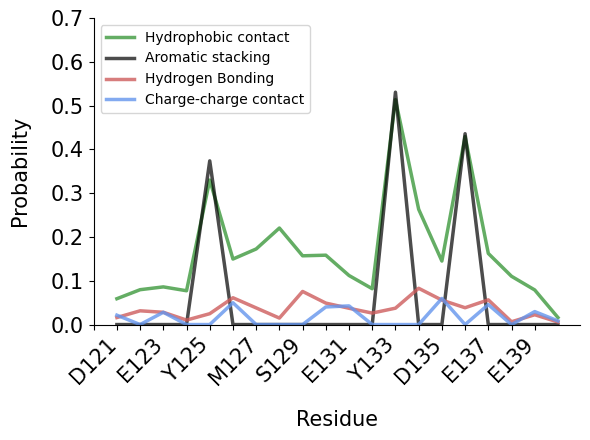

In [5]:
contacts[1] = analyse(1)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[1], weights)

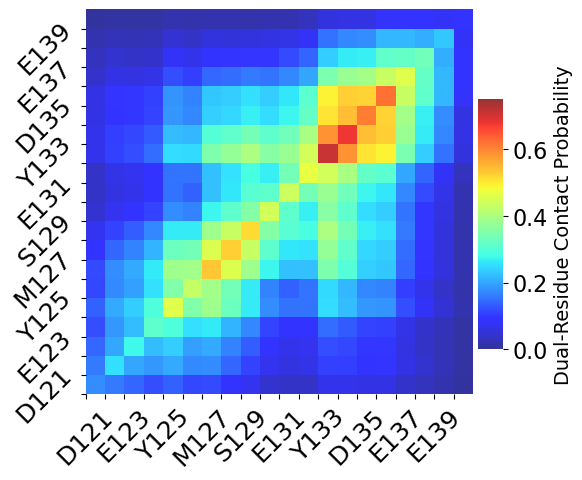

In [6]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[1]['dual'], weights)

## Ligand 2

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 2: 5000 frames, 20 residues


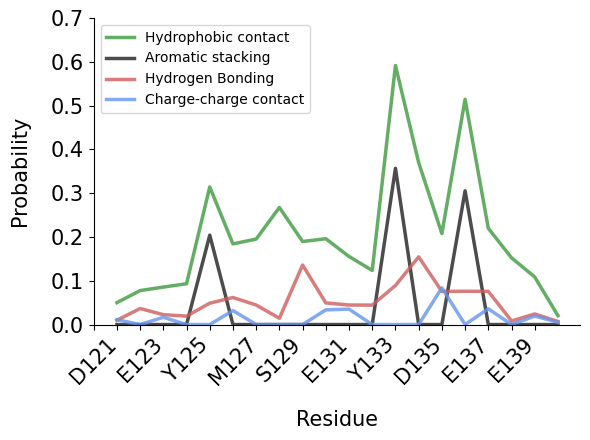

In [7]:
contacts[2] = analyse(2)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[2], weights)

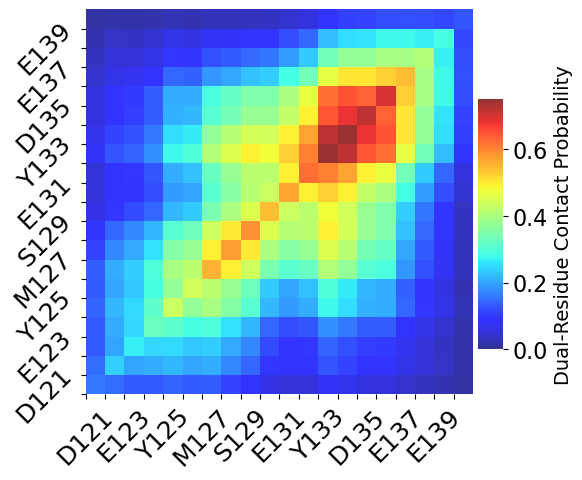

In [8]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[2]['dual'], weights)

## Ligand 4

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 4: 5000 frames, 20 residues


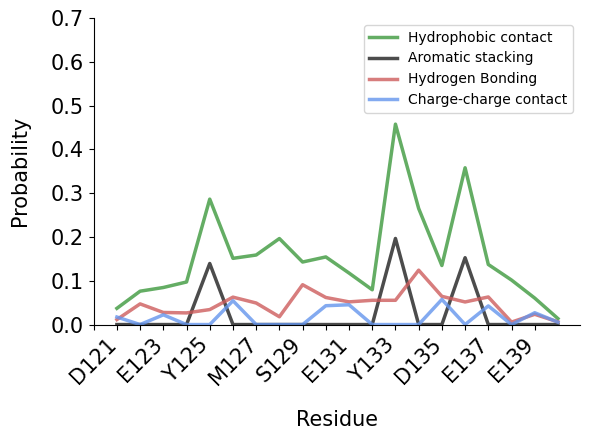

In [9]:
contacts[4] = analyse(4)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[4], weights)

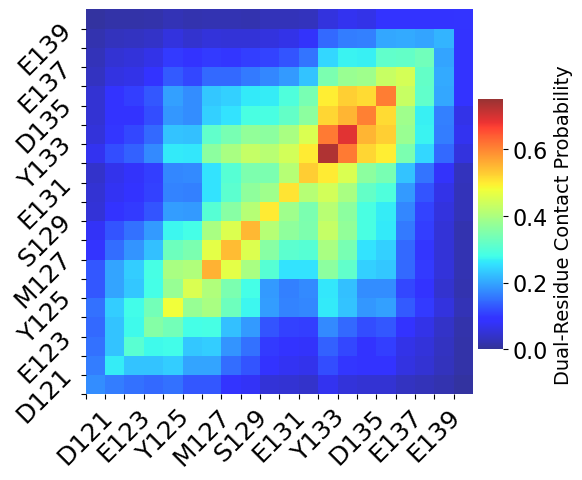

In [10]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[4]['dual'], weights)

## Ligand 6

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 6: 5000 frames, 20 residues


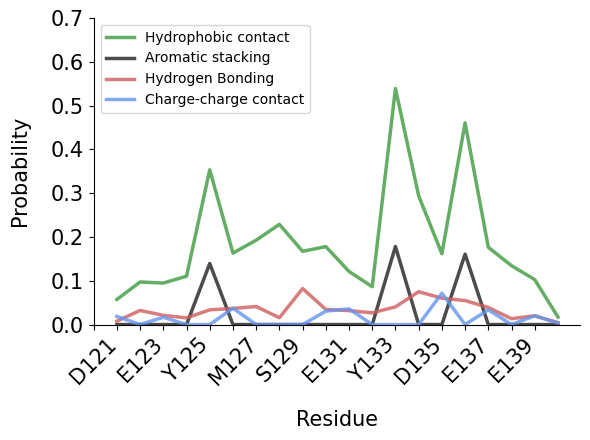

In [11]:
contacts[6] = analyse(6)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[6], weights)

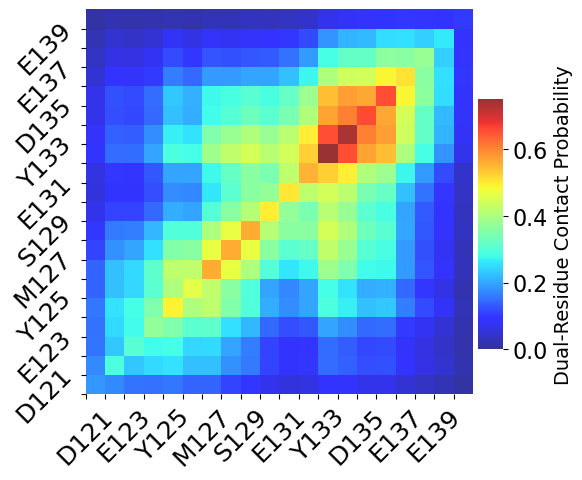

In [12]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[6]['dual'], weights)

## Ligand 7

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 7: 5000 frames, 20 residues


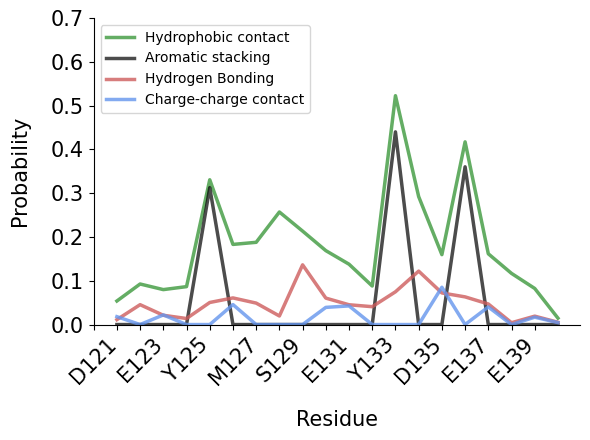

In [13]:
contacts[7] = analyse(7)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[7], weights)

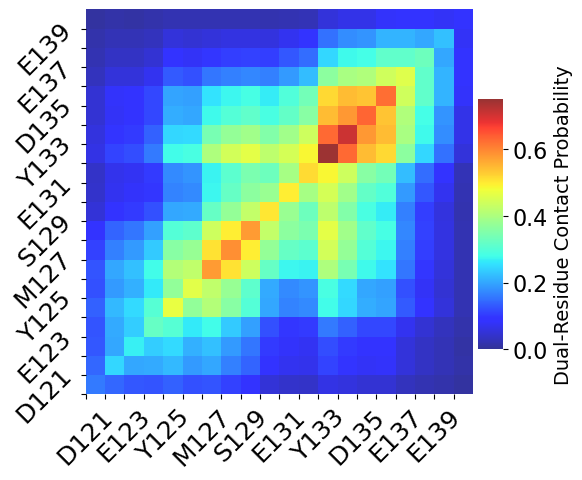

In [14]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[7]['dual'], weights)

## Ligand 8

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 8: 5000 frames, 20 residues


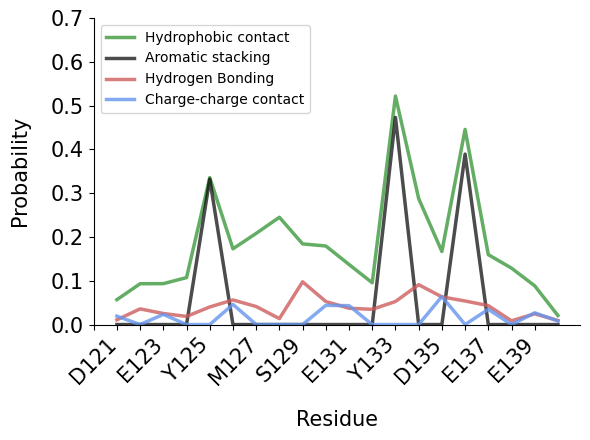

In [15]:
contacts[8] = analyse(8)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[8], weights)

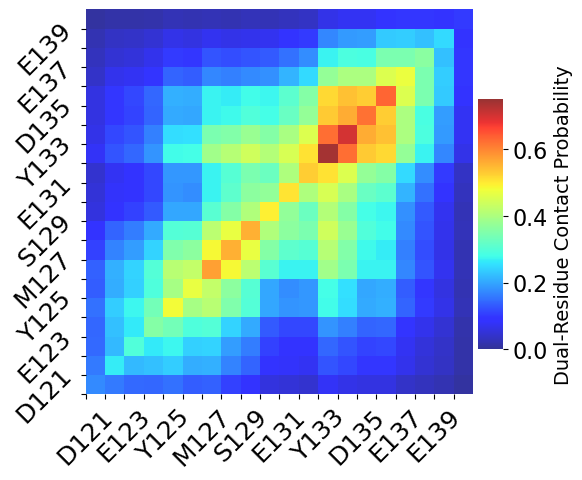

In [16]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[8]['dual'], weights)

## Ligand 10

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 10: 5000 frames, 20 residues


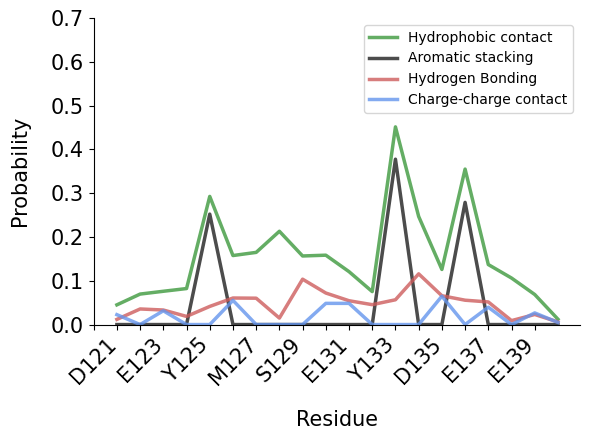

In [17]:
contacts[10] = analyse(10)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[10], weights)

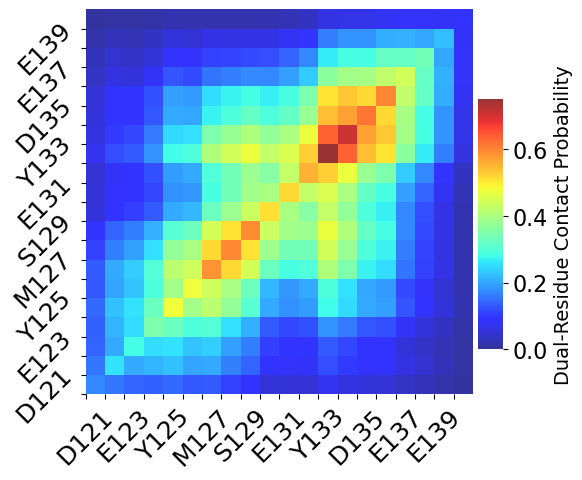

In [18]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[10]['dual'], weights)

## Ligand 11

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 11: 5000 frames, 20 residues


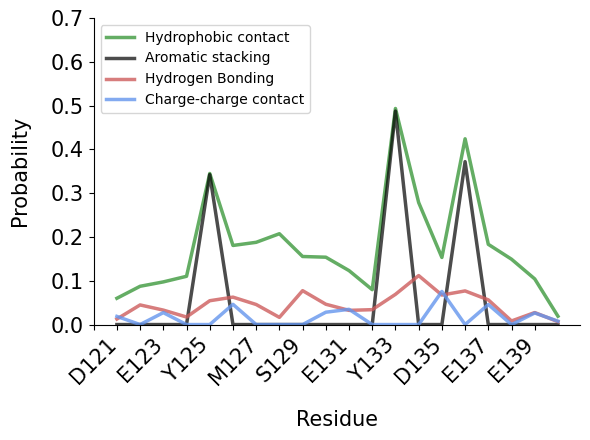

In [19]:
contacts[11] = analyse(11)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[11], weights)

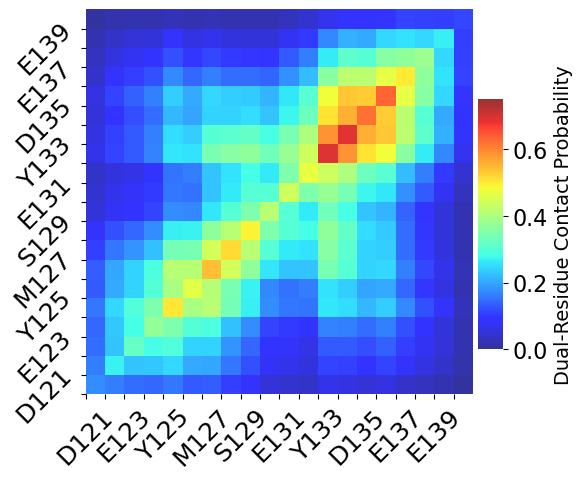

In [20]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[11]['dual'], weights)

## Ligand 12

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 12: 5000 frames, 20 residues


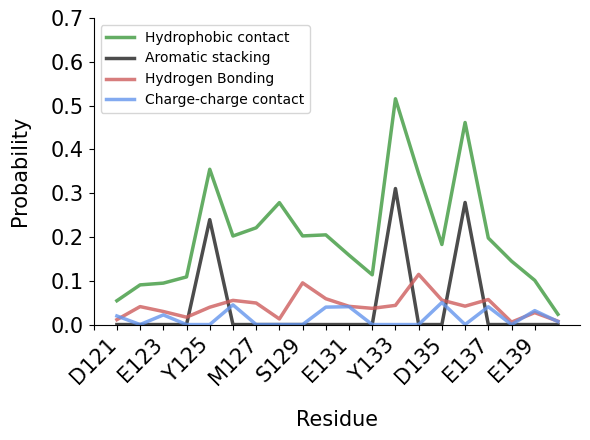

In [21]:
contacts[12] = analyse(12)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[12], weights)

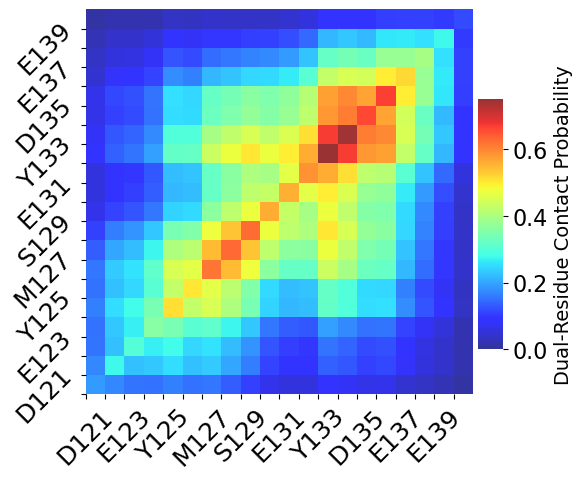

In [22]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[12]['dual'], weights)

## Ligand 13

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 13: 5000 frames, 20 residues


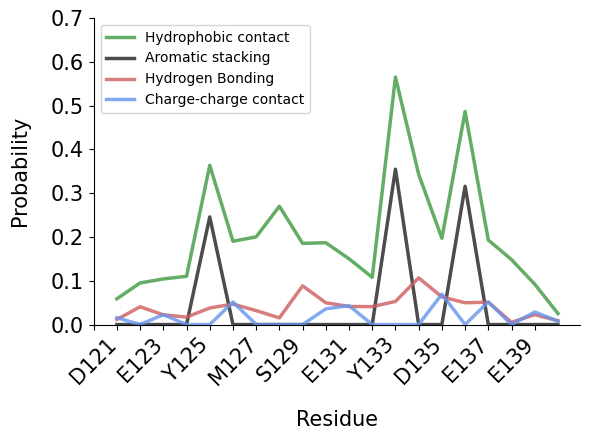

In [23]:
contacts[13] = analyse(13)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[13], weights)

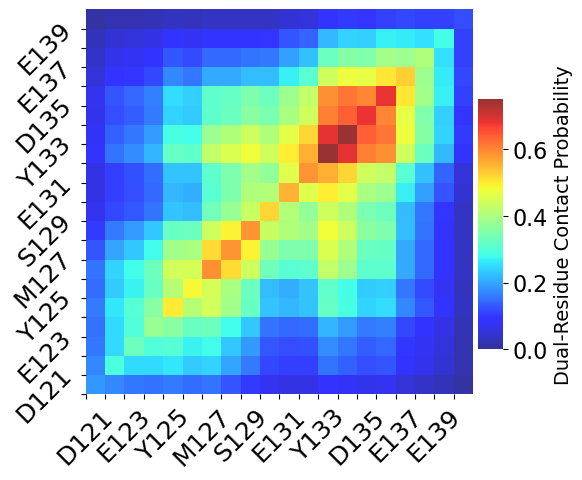

In [24]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[13]['dual'], weights)

## Ligand 14

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 14: 5000 frames, 20 residues


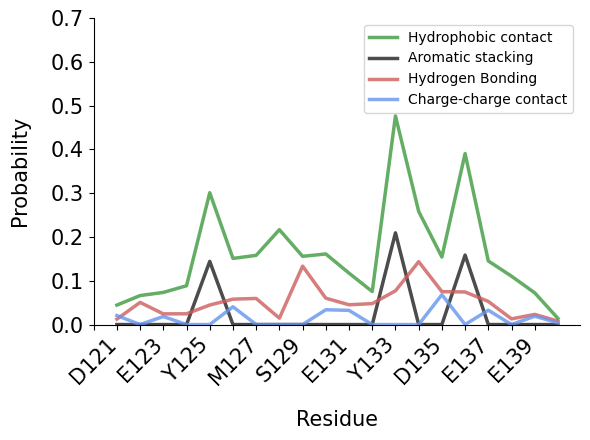

In [25]:
contacts[14] = analyse(14)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[14], weights)

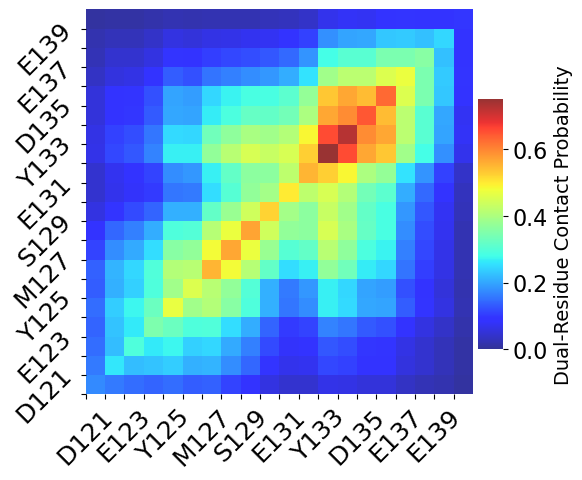

In [26]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[14]['dual'], weights)

## Ligand 15

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 15: 5000 frames, 20 residues


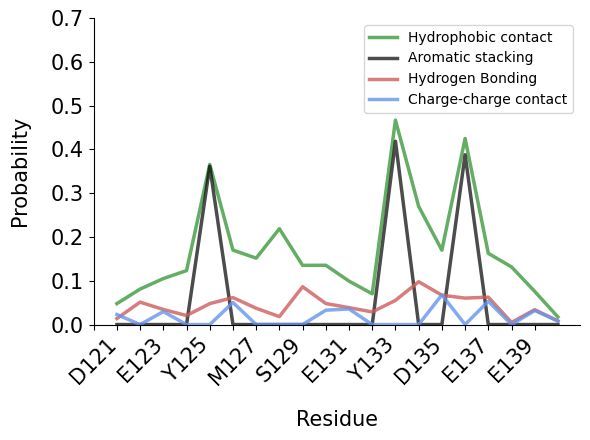

In [27]:
contacts[15] = analyse(15)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[15], weights)

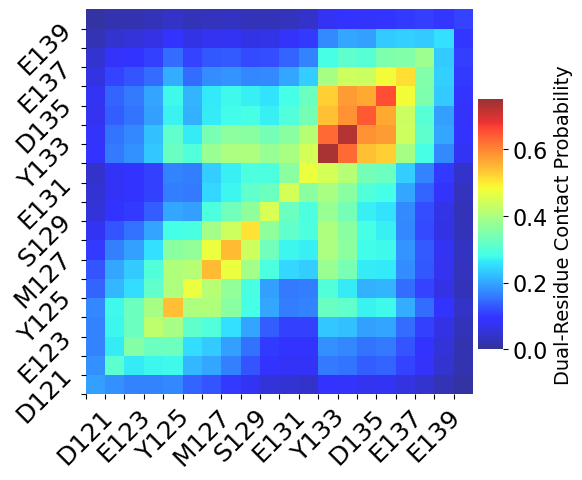

In [28]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[15]['dual'], weights)

## Ligand 16

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 16: 5000 frames, 20 residues


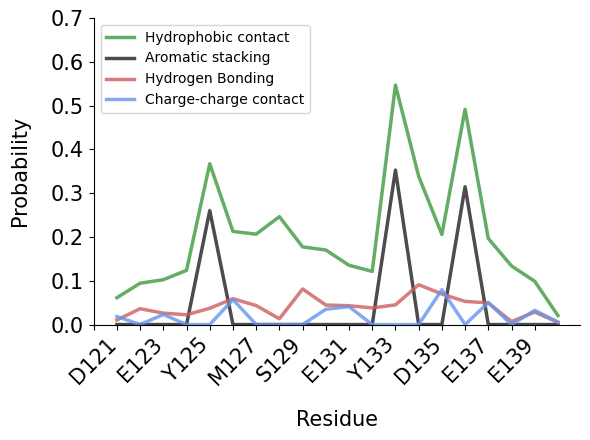

In [29]:
contacts[16] = analyse(16)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[16], weights)

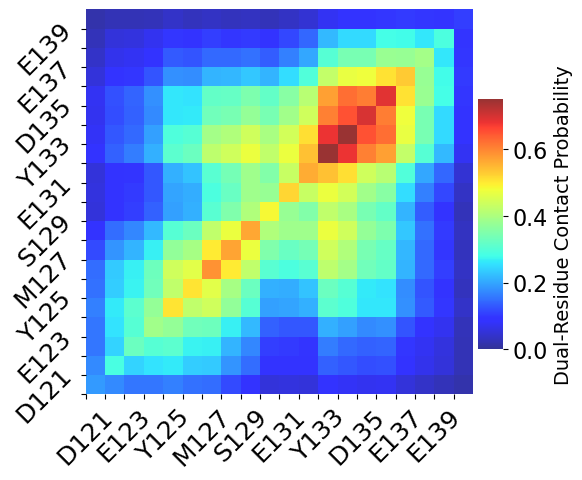

In [30]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[16]['dual'], weights)

## Ligand 18

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 18: 5000 frames, 20 residues


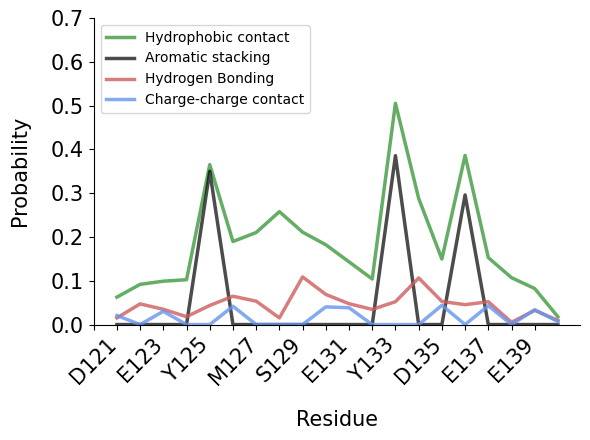

In [31]:
contacts[18] = analyse(18)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[18], weights)

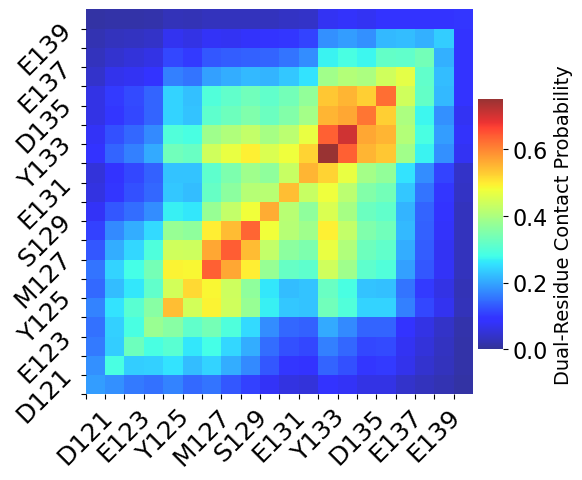

In [32]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[18]['dual'], weights)

## Ligand 19

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 19: 5000 frames, 20 residues


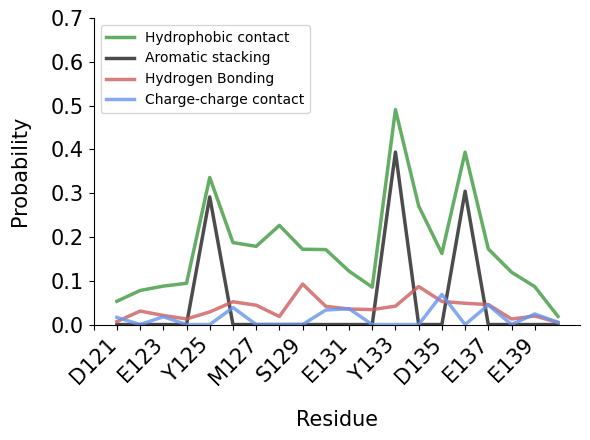

In [33]:
contacts[19] = analyse(19)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[19], weights)

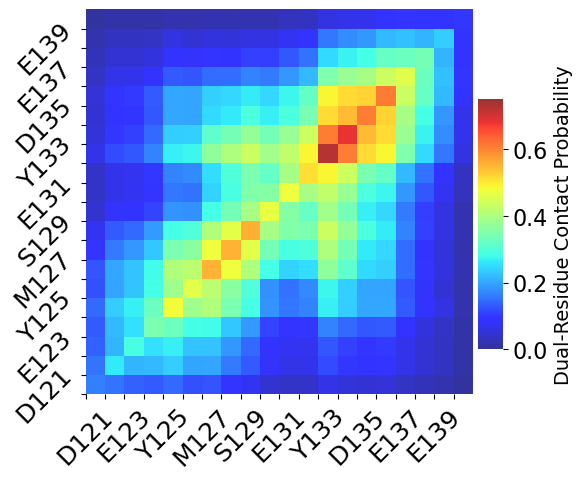

In [34]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[19]['dual'], weights)

## Ligand 20

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 20: 5000 frames, 20 residues


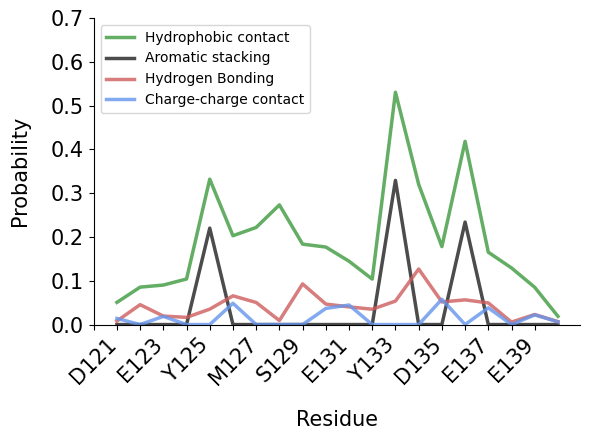

In [35]:
contacts[20] = analyse(20)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[20], weights)

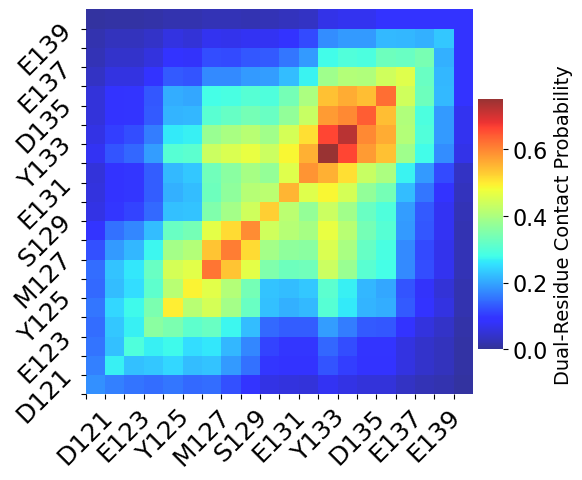

In [36]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[20]['dual'], weights)

## Ligand 21

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 21: 5000 frames, 20 residues


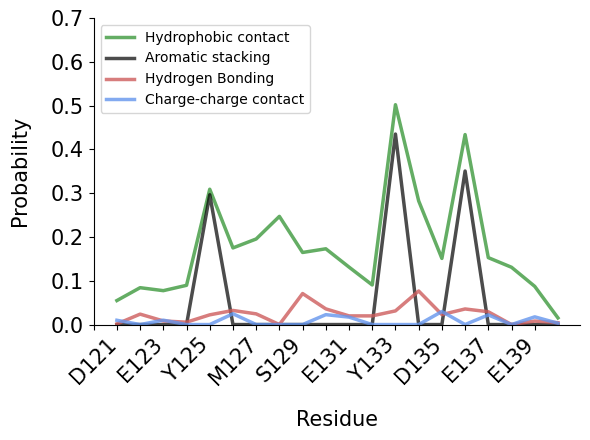

In [37]:
contacts[21] = analyse(21)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[21], weights)

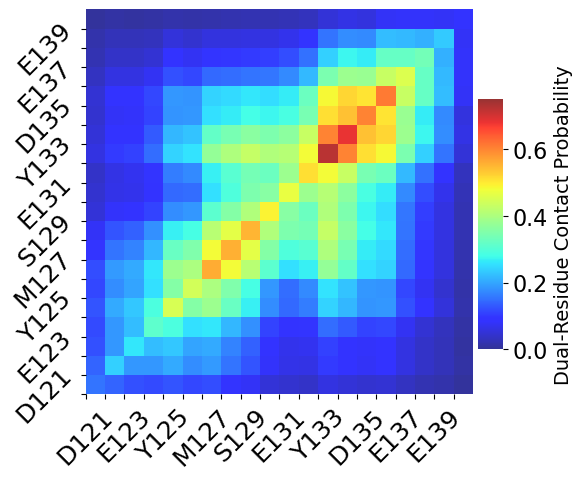

In [38]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[21]['dual'], weights)

## Ligand 22

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 22: 5000 frames, 20 residues


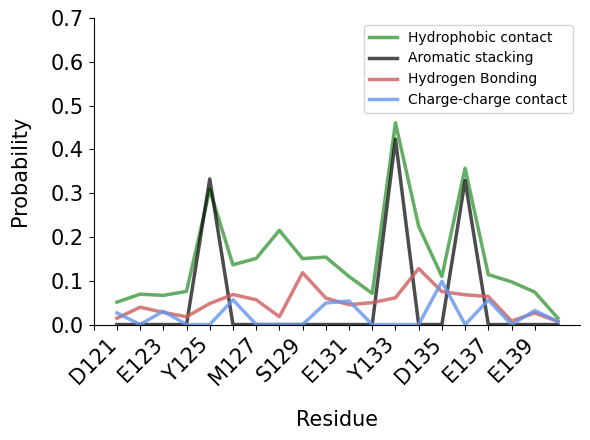

In [39]:
contacts[22] = analyse(22)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[22], weights)

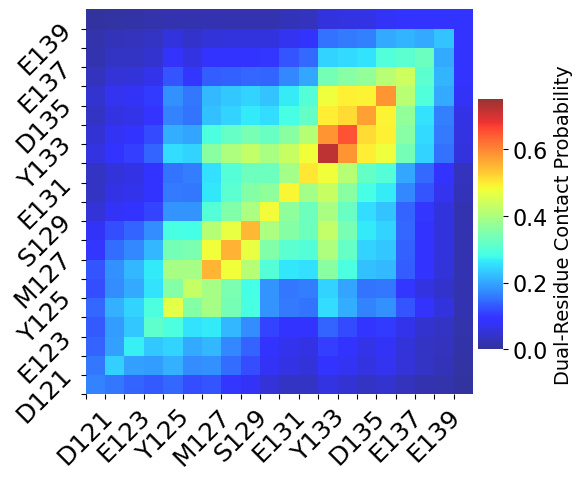

In [40]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[22]['dual'], weights)

## Ligand 25

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 25: 5000 frames, 20 residues


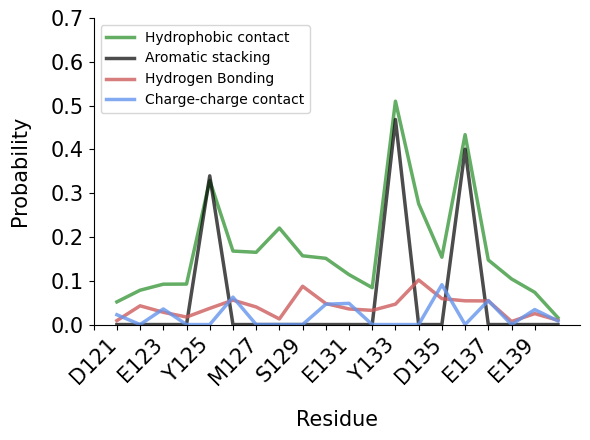

In [41]:
contacts[25] = analyse(25)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[25], weights)

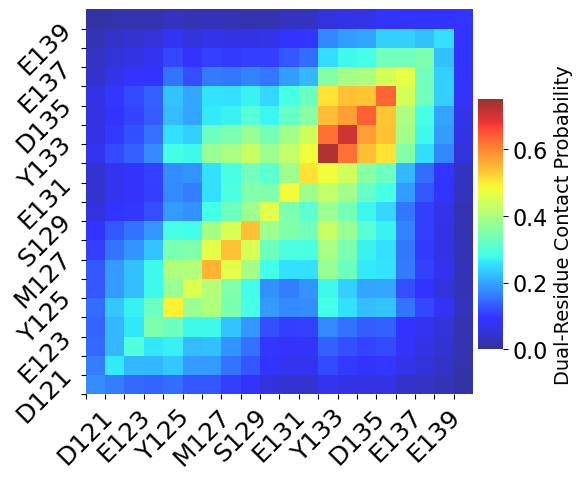

In [42]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[25]['dual'], weights)

## Ligand 26

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 26: 5000 frames, 20 residues


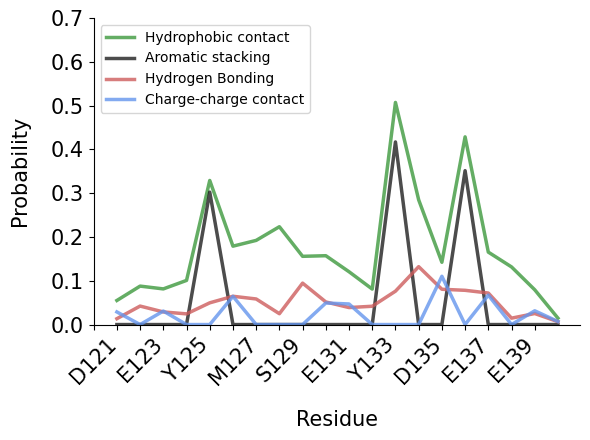

In [43]:
contacts[26] = analyse(26)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[26], weights)

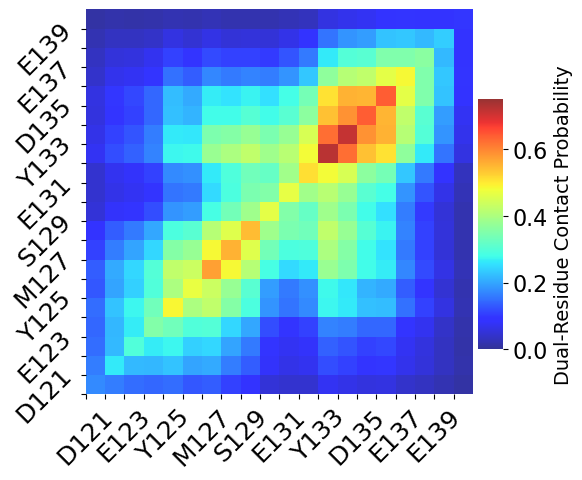

In [44]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[26]['dual'], weights)

## Ligand 27

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 27: 5000 frames, 20 residues


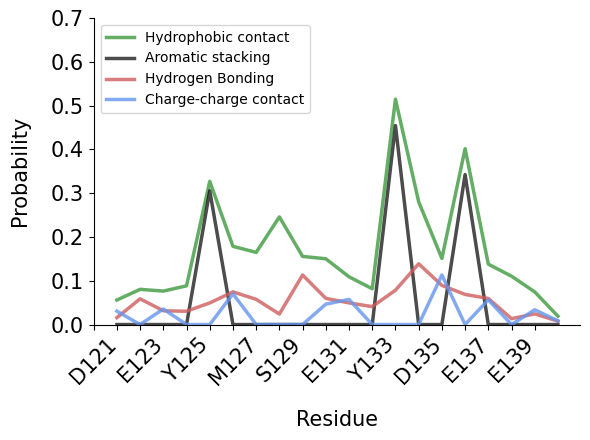

In [45]:
contacts[27] = analyse(27)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[27], weights)

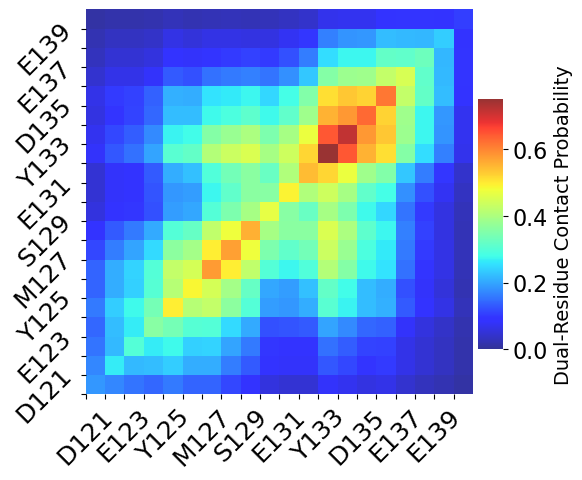

In [46]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[27]['dual'], weights)

## Ligand 29

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 29: 5000 frames, 20 residues


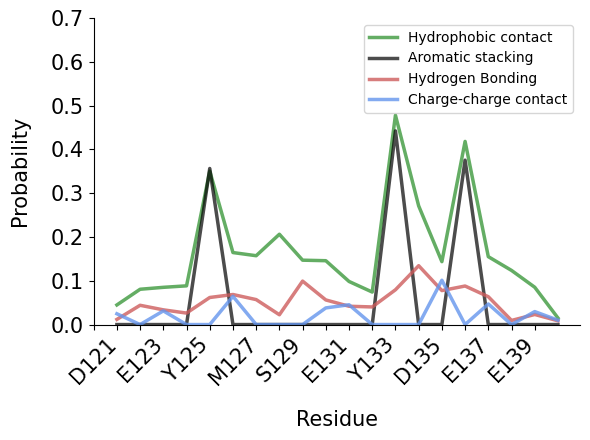

In [47]:
contacts[29] = analyse(29)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[29], weights)

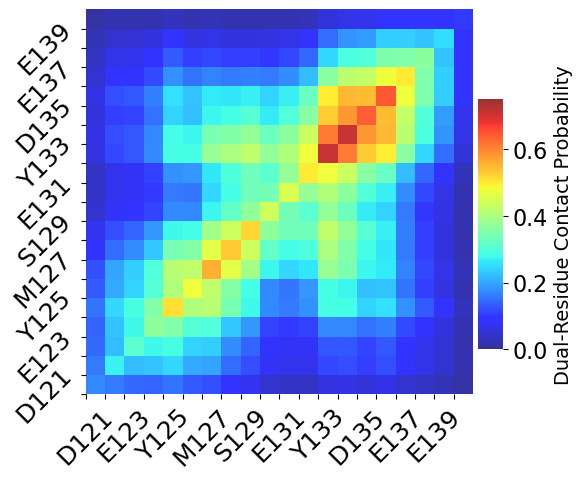

In [48]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[29]['dual'], weights)

## Ligand 30

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 30: 5000 frames, 20 residues


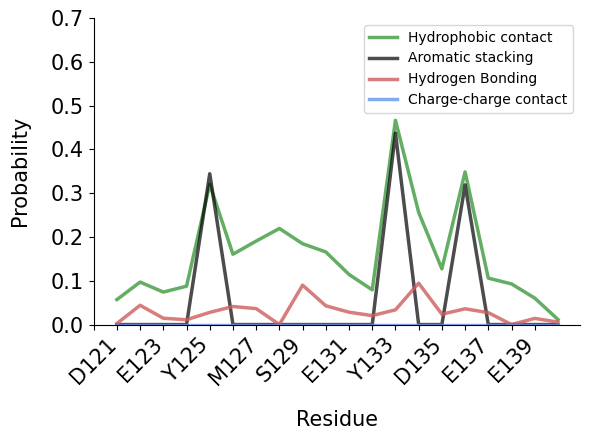

In [49]:
contacts[30] = analyse(30)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[30], weights)

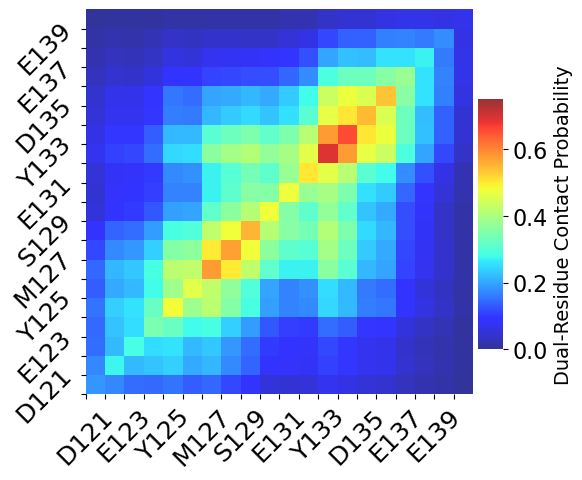

In [50]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[30]['dual'], weights)

## Ligand 33

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 33: 5000 frames, 20 residues


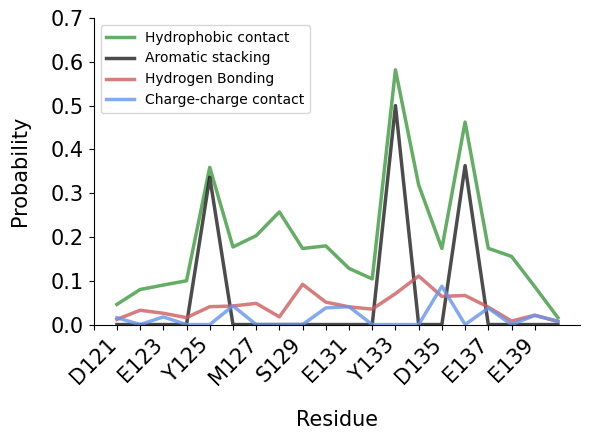

In [51]:
contacts[33] = analyse(33)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[33], weights)

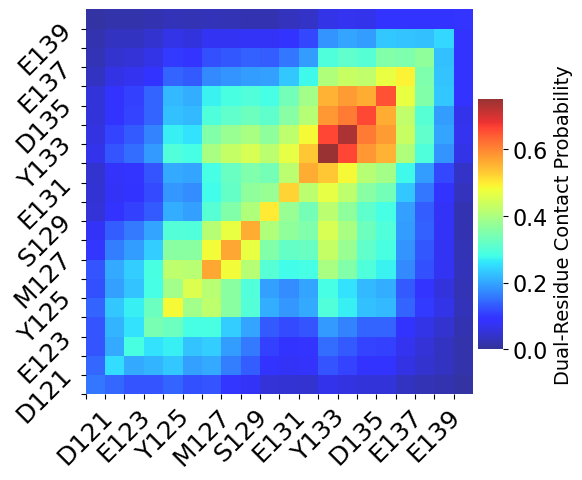

In [52]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[33]['dual'], weights)

## Ligand 35

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 35: 5000 frames, 20 residues


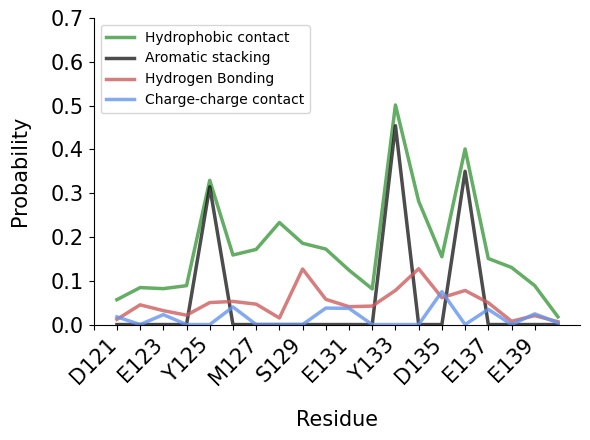

In [53]:
contacts[35] = analyse(35)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[35], weights)

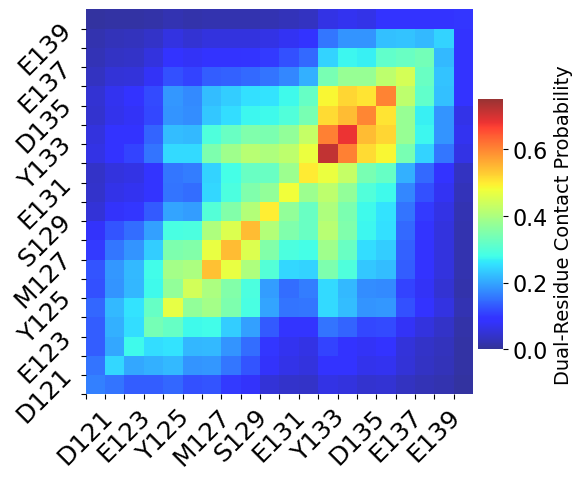

In [54]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[35]['dual'], weights)

## Ligand 36

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 36: 5000 frames, 20 residues


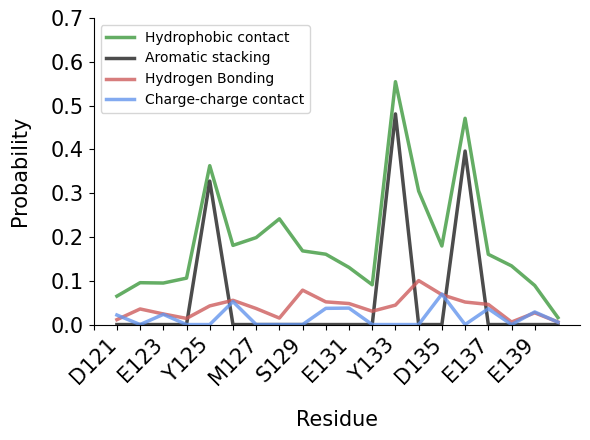

In [55]:
contacts[36] = analyse(36)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[36], weights)

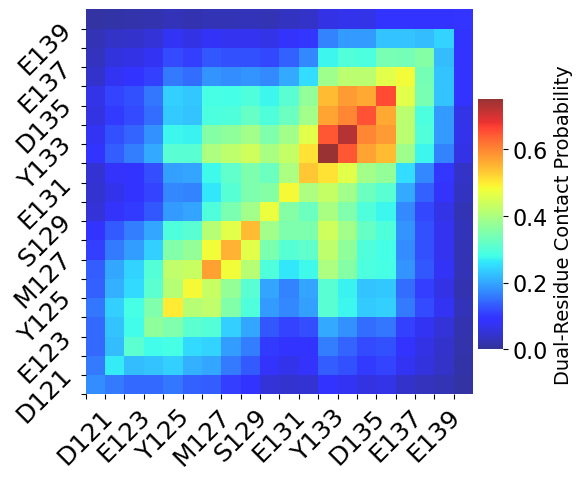

In [56]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[36]['dual'], weights)

## Ligand 37

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 37: 5000 frames, 20 residues


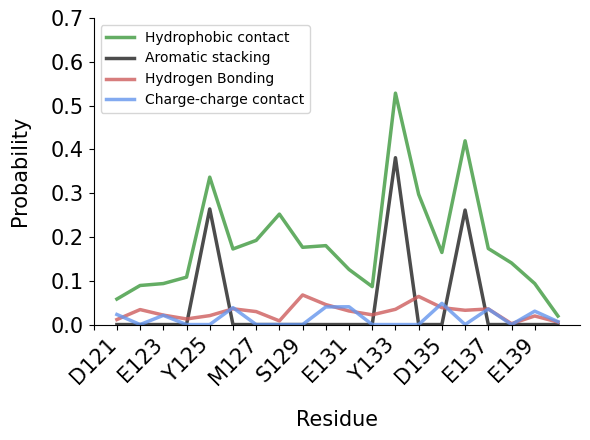

In [57]:
contacts[37] = analyse(37)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[37], weights)

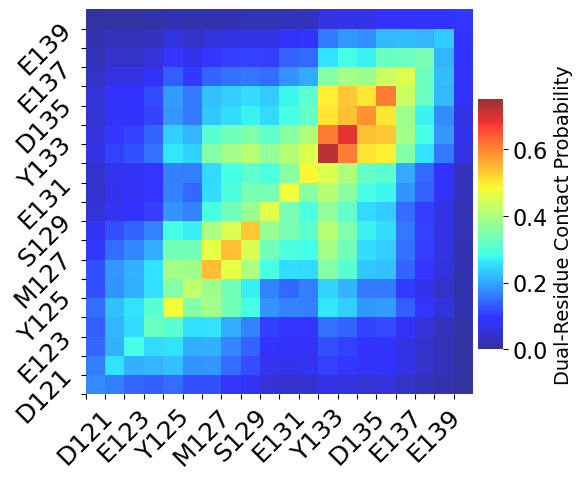

In [58]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[37]['dual'], weights)

## Ligand 39

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 39: 5000 frames, 20 residues


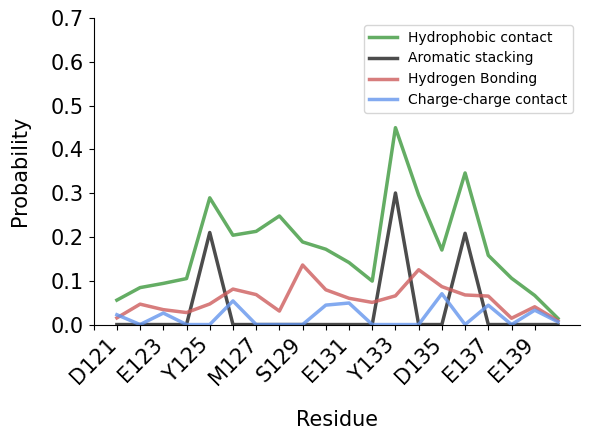

In [59]:
contacts[39] = analyse(39)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[39], weights)

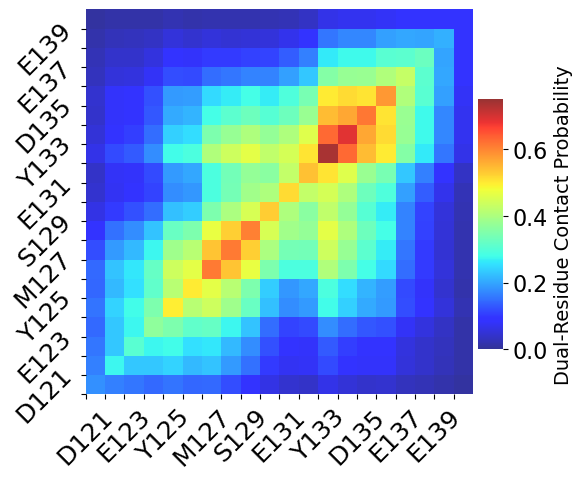

In [60]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[39]['dual'], weights)

## Ligand 46

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 46: 5000 frames, 20 residues


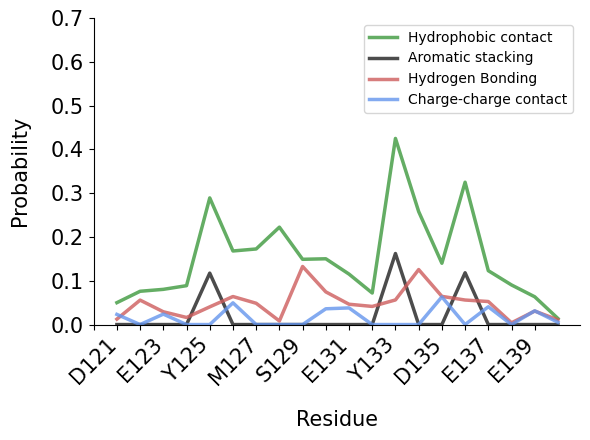

In [61]:
contacts[46] = analyse(46)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[46], weights)

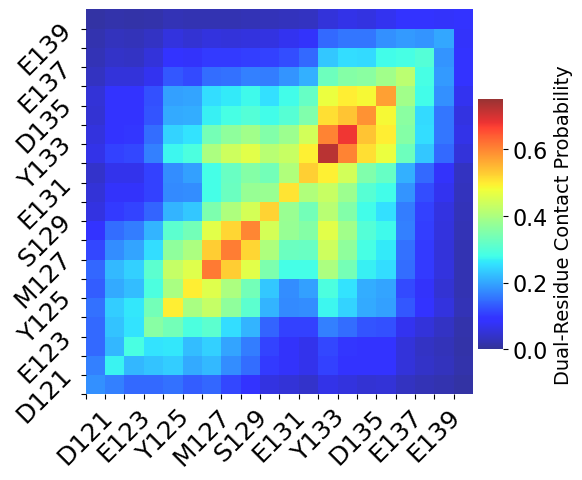

In [62]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[46]['dual'], weights)

## Ligand 48

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 48: 5000 frames, 20 residues


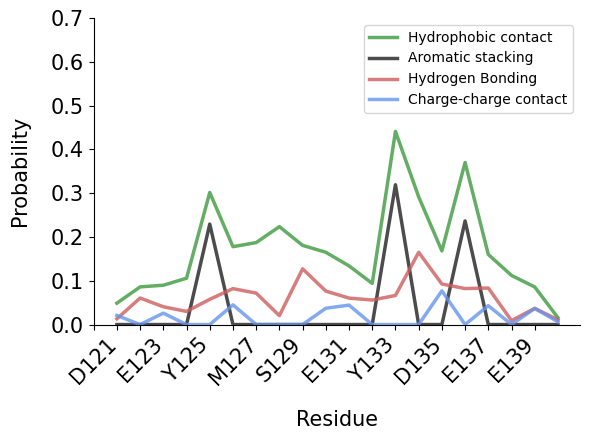

In [63]:
contacts[48] = analyse(48)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[48], weights)

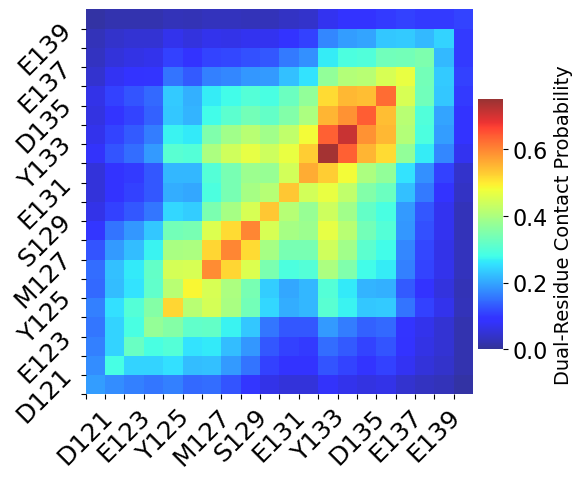

In [64]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[48]['dual'], weights)

## Ligand 49

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 49: 5000 frames, 20 residues


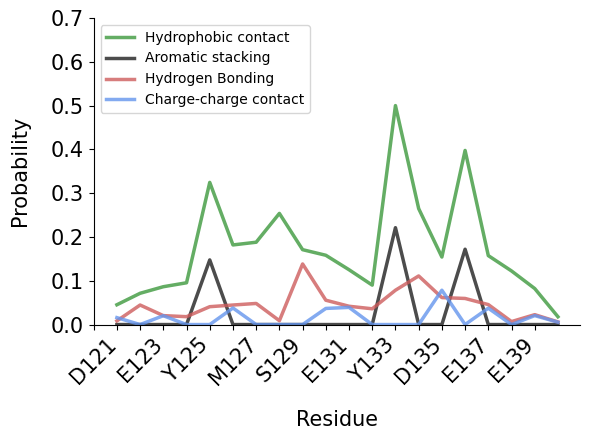

In [65]:
contacts[49] = analyse(49)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[49], weights)

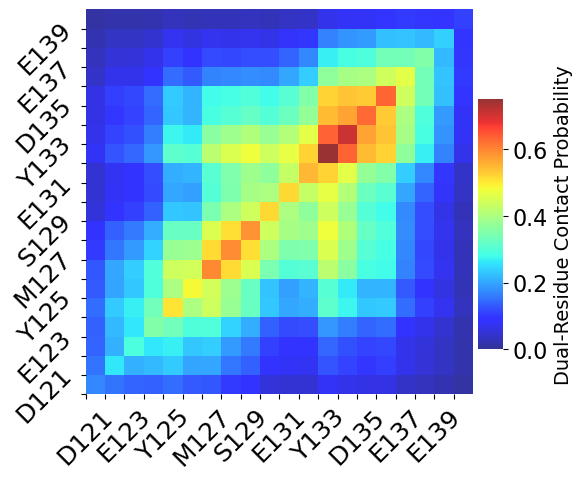

In [66]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[49]['dual'], weights)

## Ligand 50

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 50: 5000 frames, 20 residues


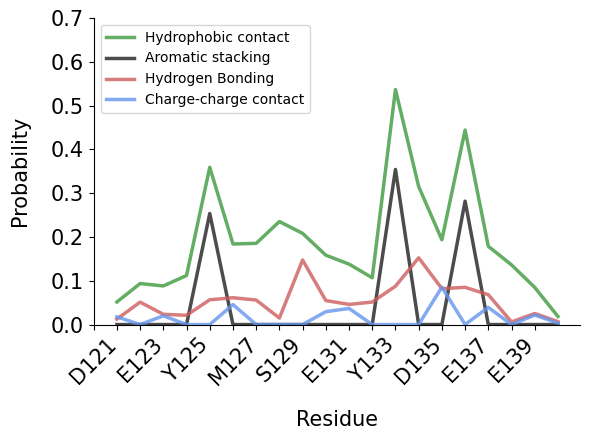

In [67]:
contacts[50] = analyse(50)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[50], weights)

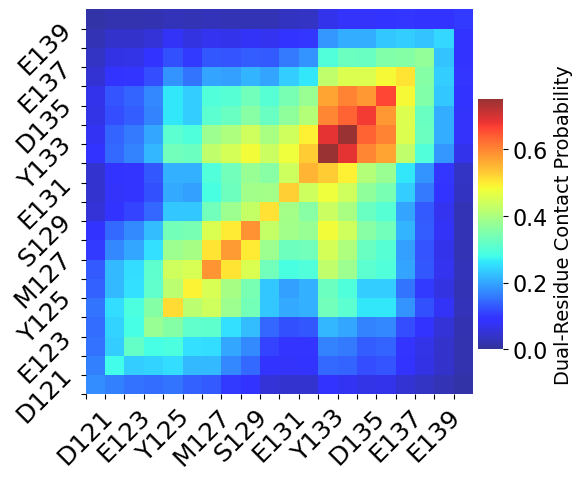

In [68]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[50]['dual'], weights)

## Ligand 51

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 51: 5000 frames, 20 residues


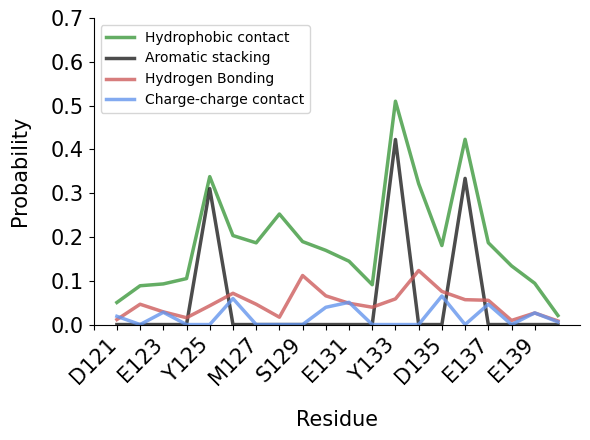

In [69]:
contacts[51] = analyse(51)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[51], weights)

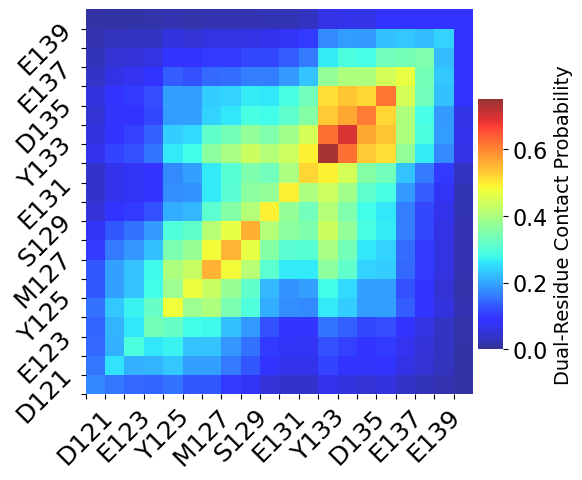

In [70]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[51]['dual'], weights)

## Ligand 52

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 52: 5000 frames, 20 residues


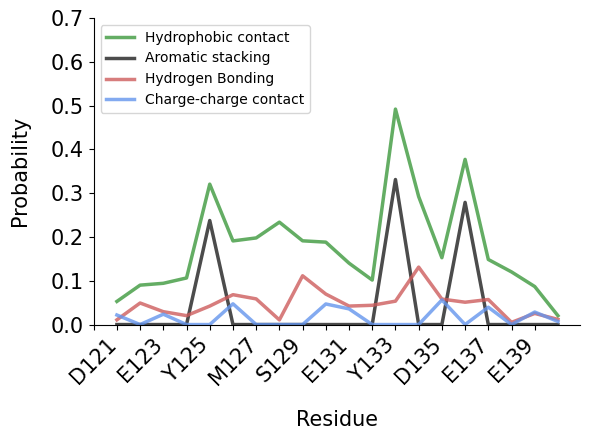

In [71]:
contacts[52] = analyse(52)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[52], weights)

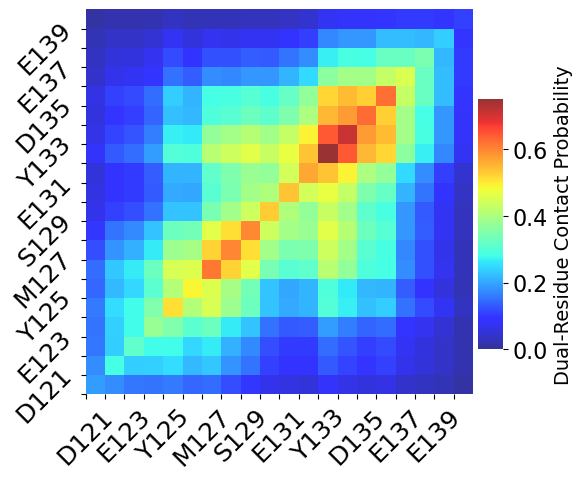

In [72]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[52]['dual'], weights)

## Ligand 54

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 54: 5000 frames, 20 residues


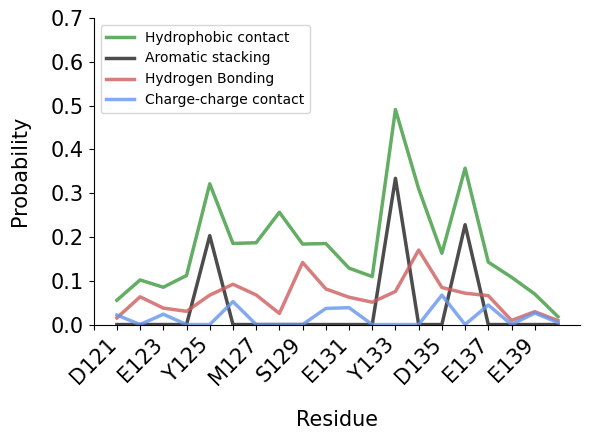

In [73]:
contacts[54] = analyse(54)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[54], weights)

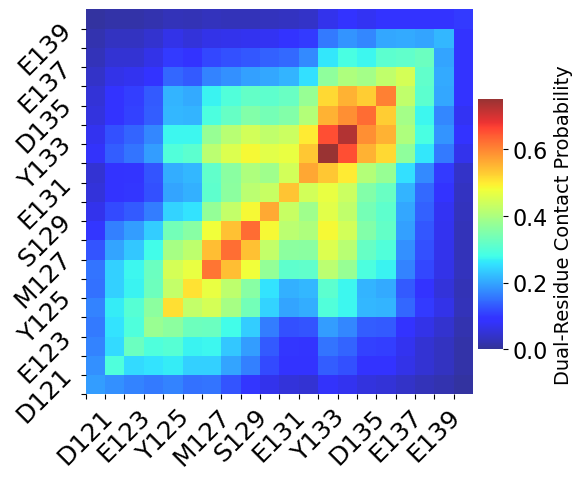

In [74]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[54]['dual'], weights)

## Ligand 55

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 55: 5000 frames, 20 residues


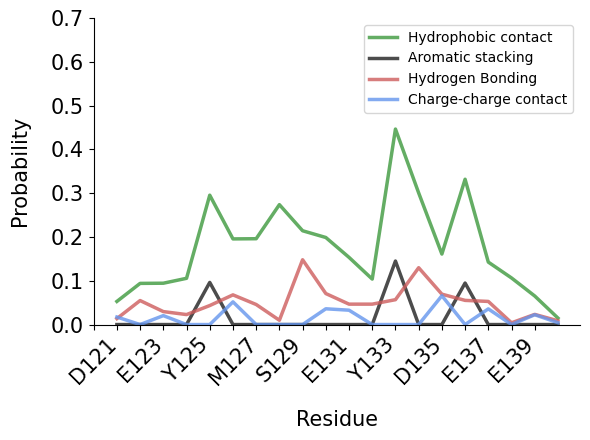

In [75]:
contacts[55] = analyse(55)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[55], weights)

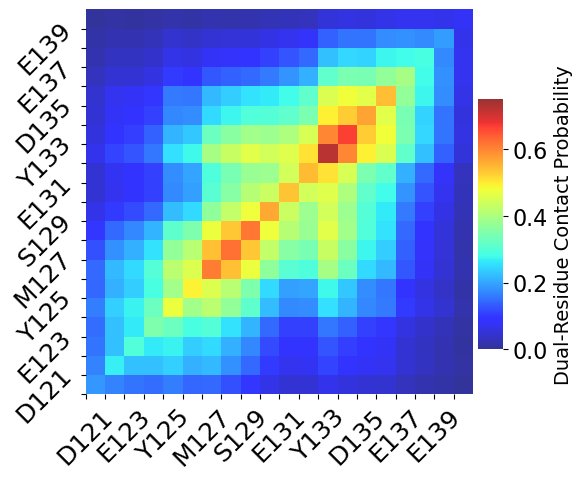

In [76]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[55]['dual'], weights)

## Ligand 56

Populations of intermolecular interactions and ligand dual residue contact probability, ensemble average.

ligand 56: 5000 frames, 20 residues


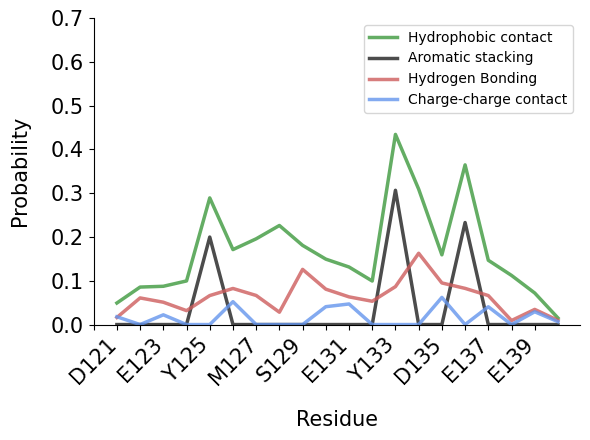

In [77]:
contacts[56] = analyse(56)
# intermolecular interactions
plotting.plot_ensemble_ii(contacts[56], weights)

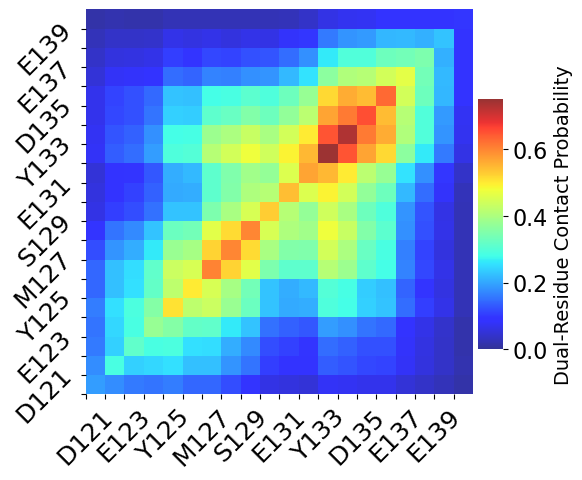

In [78]:
# ligand dual residue contact probability
plotting.plot_ensemble_dual(contacts[56]['dual'], weights)